> **Portfolio summary:** Box-Jenkins ARIMA modelling of HSBC's share price, tested out of sample against a random walk (group project).
>
> [Project README](README.md) · [Back to the portfolio](../README.md)

# ARIMA Modelling of HSBC Stock Prices (1999–2002)

This notebook fits an ARIMA time series model to daily HSBC stock prices and evaluates out-of-sample performance via one-step-ahead rolling forecasts.

1. **Data loading and train/test split**
2. **Stationarity and volatility inspection**
3. **ACF / PACF analysis**
4. **Model selection** — manual AIC comparison and auto_arima
5. **Residual diagnostics** — Ljung-Box test
6. **Rolling one-step-ahead forecasting and evaluation**

> **Dataset:** Daily adjusted closing prices for HSBC, CLP, and CK Hutchison (Jan 1999 – Dec 2002).

## 1. Imports and Plot Settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
import pmdarima as pm

plt.rc('font', size=14)
plt.rc('axes', titlesize=20, labelsize=16)
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)

## 2. Load Data and Create Train / Test Split

- **Training set:** Jan 1999 – Dec 2001 (~3 years, ~740 trading days)
- **Test set:** Jan 2002 – Dec 2002 (~1 year, ~244 trading days)

We use HSBC as it is the most liquid stock in the dataset.

In [2]:
df = pd.read_csv("stock_1999_2002 (1).txt")
df.columns = ["Date", "HSBC", "CLP", "CK"]
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df = df.set_index("Date").sort_index()

price = df["HSBC"]

train = price[price.index < "2002-01-01"]
test = price[price.index >= "2002-01-01"]

print(f"Training: {train.index[0].date()} to {train.index[-1].date()} ({len(train)} obs)")
print(f"Test:     {test.index[0].date()} to {test.index[-1].date()} ({len(test)} obs)")

Training: 1999-01-04 to 2001-12-31 (737 obs)
Test:     2002-01-02 to 2002-12-31 (247 obs)

## 3. Visualise Price Level and Rolling Volatility

We plot the full HSBC price series with the train/test boundary, and a 20-day rolling standard deviation to inspect volatility regimes.

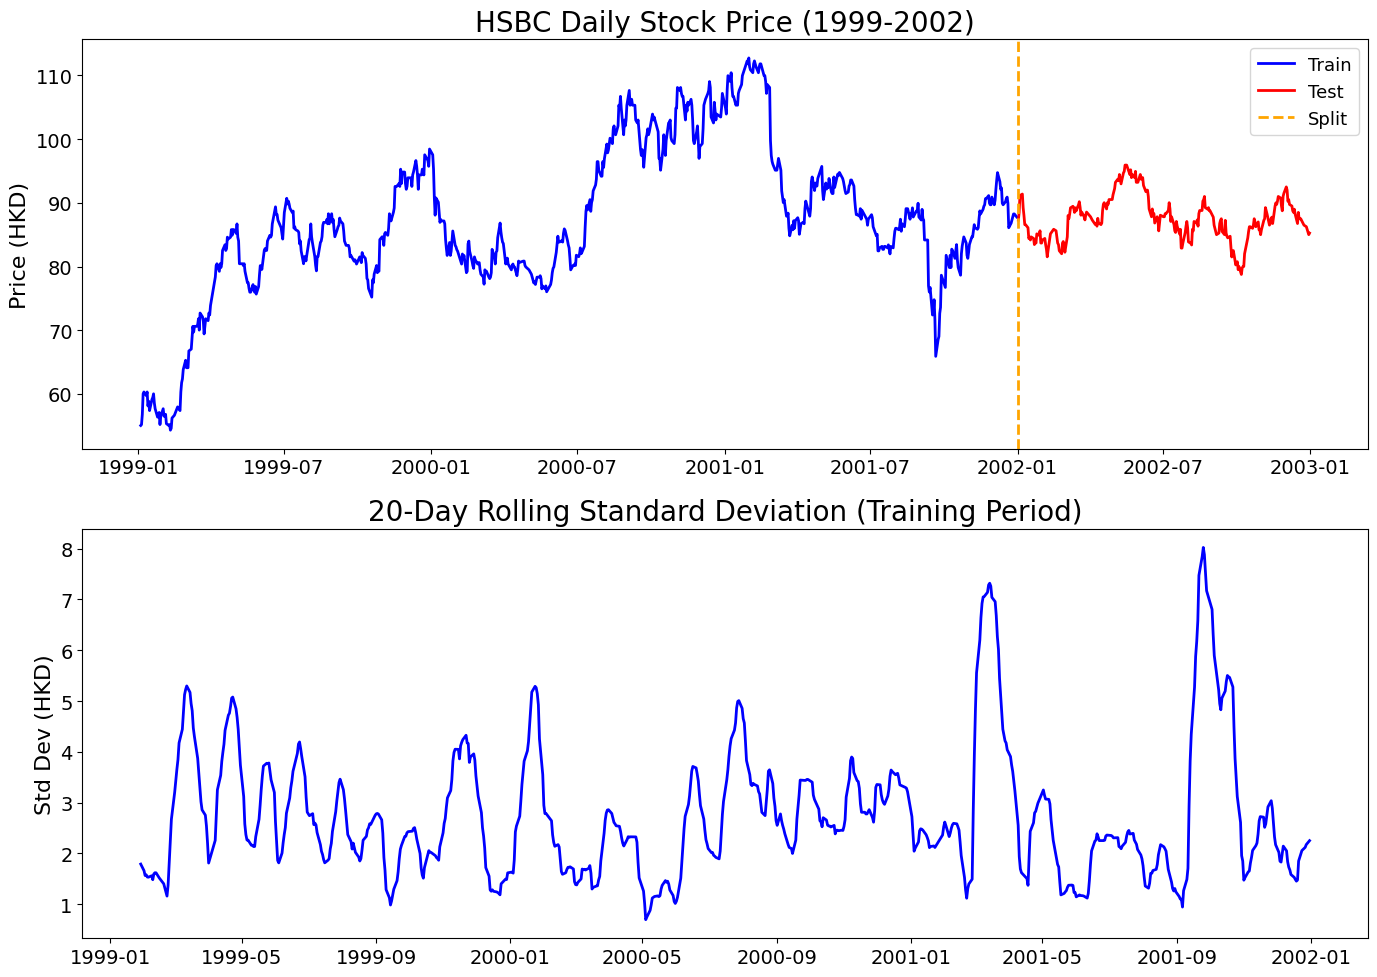

In [3]:
fig, (ax1, ax2) = plt.subplots(nrows=2, figsize=(14, 10))

ax1.plot(train.index, train.values, "b-", linewidth=2, label="Train")
ax1.plot(test.index, test.values, "r-", linewidth=2, label="Test")
ax1.axvline(pd.Timestamp("2002-01-01"), color="orange", linestyle="--", linewidth=2, label="Split")
ax1.set_title("HSBC Daily Stock Price (1999-2002)")
ax1.set_ylabel("Price (HKD)")
ax1.legend(fontsize=13)

win = 20
rolling_std = train.rolling(win).std(ddof=1)
ax2.plot(rolling_std.index, rolling_std.values, "b-", linewidth=2)
ax2.set_title(f"{win}-Day Rolling Standard Deviation (Training Period)")
ax2.set_ylabel("Std Dev (HKD)")

fig.tight_layout()
fig.savefig("HSBC_price_and_volatility.png", dpi=200)
plt.show()

## 4. ACF of the Price Level — Testing for a Unit Root

A slowly decaying ACF indicates non-stationarity, confirming the need for differencing (d >= 1).

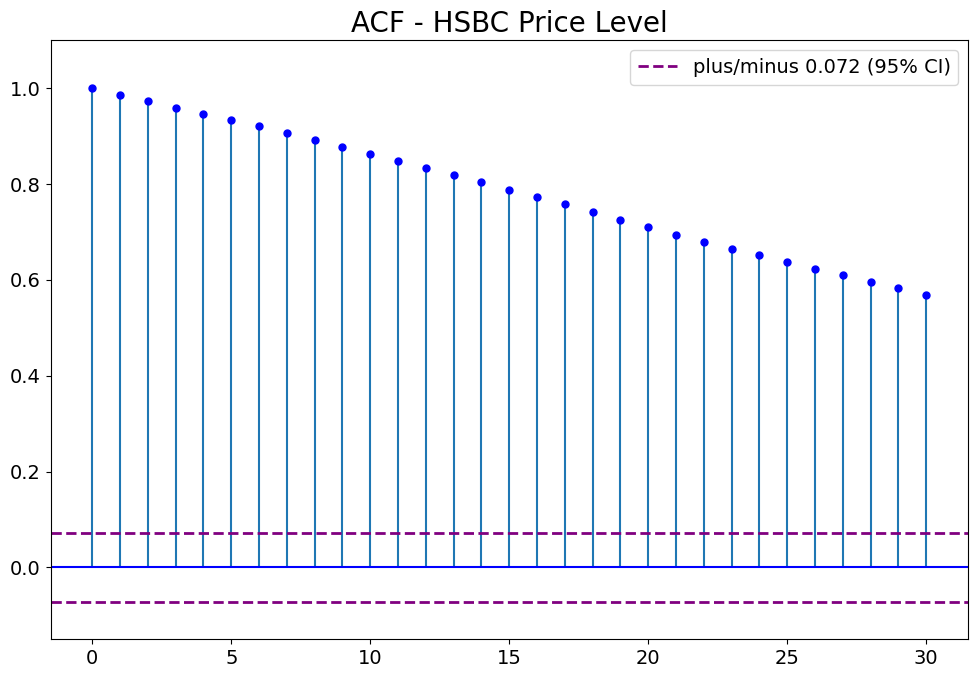

In [4]:
alpha = 0.05
c_i = stats.norm.ppf(1 - alpha / 2) / np.sqrt(len(train))

fig, ax = plt.subplots(figsize=(10, 7))
plot_acf(train.values, lags=30, ax=ax, alpha=None, color="blue",
         title="ACF - HSBC Price Level")
ax.set_ylim((-0.15, 1.1))
ax.axhline( c_i, linestyle="--", c="purple", linewidth=2, label=f"plus/minus {c_i:.3f} (95% CI)")
ax.axhline(-c_i, linestyle="--", c="purple", linewidth=2)
ax.legend()
fig.tight_layout()
fig.savefig("HSBC_ACF_level.png", dpi=200)
plt.show()

## 5. ACF and PACF of First-Differenced Prices — Choosing p and q

The slow ACF decay above confirms **d = 1**. We now examine the ACF and PACF of the first difference to identify candidate AR and MA orders.

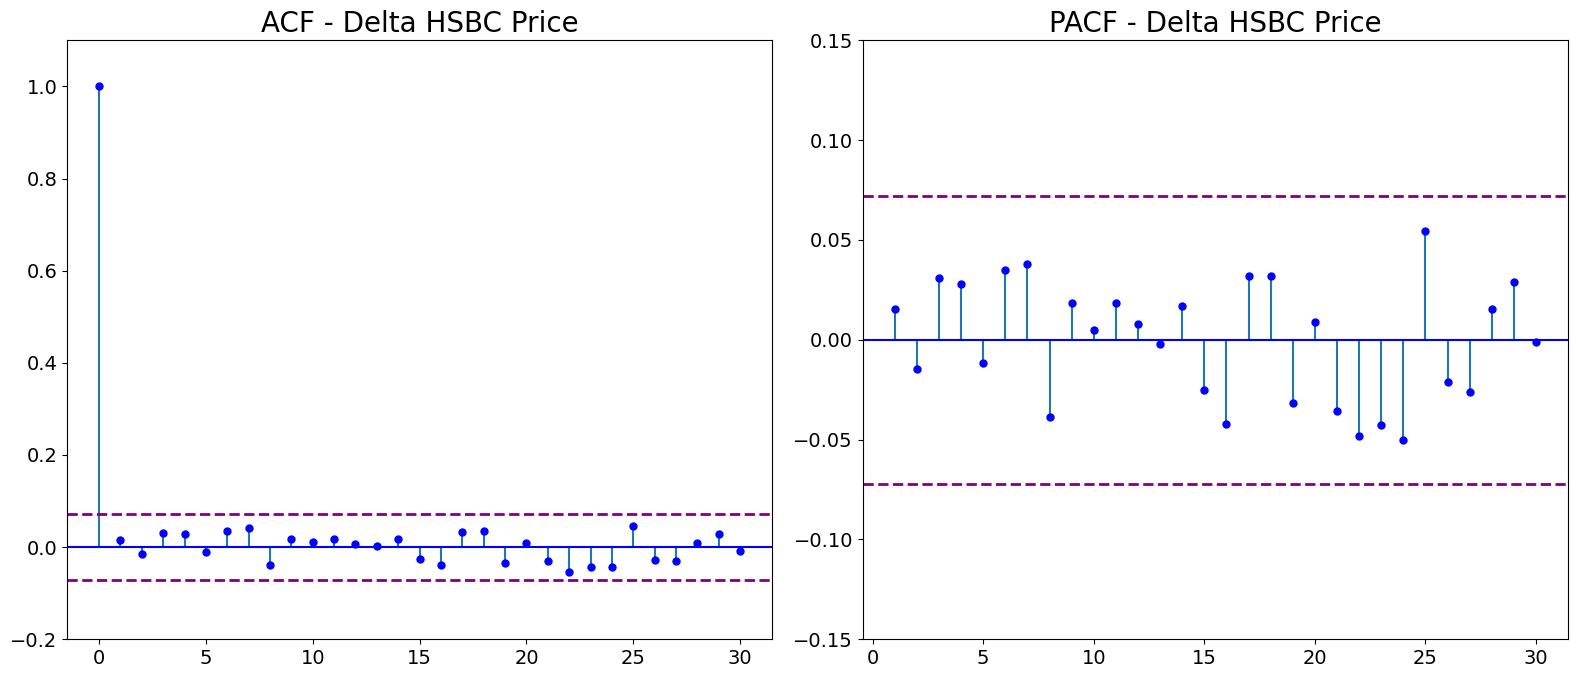

In [5]:
diff_price = train.diff().dropna().values

fig, axs = plt.subplots(ncols=2, figsize=(16, 7))

c_i_diff = stats.norm.ppf(1 - alpha / 2) / np.sqrt(len(diff_price))

plot_acf(diff_price, lags=30, ax=axs[0], alpha=None, color="blue",
         title="ACF - Delta HSBC Price")
axs[0].set_ylim((-0.2, 1.1))
axs[0].axhline( c_i_diff, linestyle="--", c="purple", linewidth=2)
axs[0].axhline(-c_i_diff, linestyle="--", c="purple", linewidth=2)

plot_pacf(diff_price, lags=30, ax=axs[1], alpha=None, zero=False,
          color="blue", title="PACF - Delta HSBC Price")
axs[1].set_ylim((-0.15, 0.15))
axs[1].axhline( c_i_diff, linestyle="--", c="purple", linewidth=2)
axs[1].axhline(-c_i_diff, linestyle="--", c="purple", linewidth=2)

fig.tight_layout()
fig.savefig("HSBC_ACF_PACF_diff.png", dpi=200)
plt.show()

## 6. Manual Model Comparison via AIC

Based on the ACF/PACF of differenced prices, we compare candidate ARIMA models using AIC (lower is better).

In [6]:
candidates = {
    "ARIMA(1,1,0)": (1, 1, 0),
    "ARIMA(0,1,1)": (0, 1, 1),
    "ARIMA(1,1,1)": (1, 1, 1),
    "ARIMA(2,1,0)": (2, 1, 0),
    "ARIMA(0,1,2)": (0, 1, 2),
    "ARIMA(2,1,2)": (2, 1, 2),
}

print(f"{'Model':<18} {'AIC':>10}")
print("-" * 30)
for name, order in candidates.items():
    aic = ARIMA(train.values, order=order).fit().aic
    print(f"{name:<18} {aic:>10.2f}")

Model                     AIC
------------------------------
ARIMA(1,1,0)          2729.90
ARIMA(0,1,1)          2729.89
ARIMA(1,1,1)          2731.70
ARIMA(2,1,0)          2731.76

ARIMA(0,1,2)          2731.74
ARIMA(2,1,2)          2734.27

## 7. Automated Model Selection with auto_arima

We use `pmdarima.auto_arima` to search over a wider grid of (p, d, q) combinations.

In [7]:
best_model = pm.auto_arima(
    train.values,
    max_p=5, max_q=5, max_d=2,
    information_criterion="aic",
    seasonal=False,
    stepwise=False,
    with_intercept=False
)

print(best_model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  737
Model:               SARIMAX(0, 1, 0)   Log Likelihood               -1363.046
Date:                Tue, 19 May 2026   AIC                           2728.091
Time:                        18:40:40   BIC                           2732.693
Sample:                             0   HQIC                          2729.866
                                - 737                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         2.3775      0.085     28.117      0.000       2.212       2.543
Ljung-Box (L1) (Q):                   0.18   Jarque-Bera (JB):               173.63
Prob(Q):                              0.67   Pr

## 8. Residual Diagnostics — Ljung-Box Test

We verify that the fitted residuals resemble white noise. The Ljung-Box test checks:
- **H0:** No autocorrelation in residuals up to lag K
- **H1:** At least one autocorrelation is nonzero

A p-value > 0.05 means we fail to reject H0.

Best model: ARIMA(0,1,0)

Ljung-Box Test Results:
     lb_stat  lb_pvalue
5   1.761474   0.881066
10  5.289255   0.871037
15  6.246345   0.975306

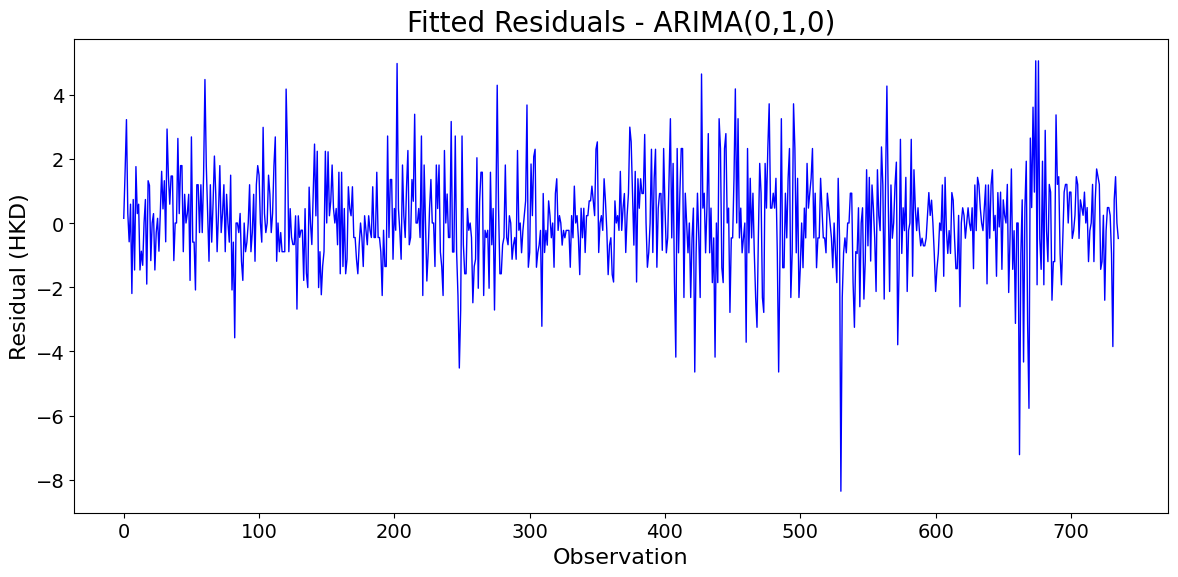

In [8]:
p, d, q = best_model.order
arima_name = f"ARIMA({p},{d},{q})"
print(f"Best model: {arima_name}")

resid = best_model.resid()[1:]

lb_result = acorr_ljungbox(resid, lags=[5, 10, 15], model_df=p + q)
print("\nLjung-Box Test Results:")
print(lb_result)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(resid, "b-", linewidth=1)
ax.set_title(f"Fitted Residuals - {arima_name}")
ax.set_ylabel("Residual (HKD)")
ax.set_xlabel("Observation")
fig.tight_layout()
fig.savefig("HSBC_residuals.png", dpi=200)
plt.show()

## 9. Rolling One-Step-Ahead Forecasting

We evaluate out-of-sample using a rolling window:
1. Start with training data as history
2. Forecast next day price
3. Append actual realised price and repeat

This mimics real-time forecasting without look-ahead bias.

In [9]:
hist_data = train.values.tolist()

arima_pred = np.empty(len(test))

for i, actual in enumerate(test.values):
    model = ARIMA(hist_data, order=best_model.order)
    model_fit = model.smooth(best_model.params())
    arima_pred[i] = model_fit.forecast()[0]
    hist_data.append(actual)
    if (i + 1) % 50 == 0:
        print(f"  Forecast {i+1}/{len(test)} complete")

print(f"\nForecasting complete - {len(arima_pred)} one-step-ahead predictions")

  Forecast 50/247 complete
  Forecast 100/247 complete

  Forecast 150/247 complete
  Forecast 200/247 complete


Forecasting complete - 247 one-step-ahead predictions

## 10. Forecast Evaluation — ARIMA vs Random Walk

We compare the ARIMA one-step-ahead forecasts against the naive random walk benchmark (tomorrow = today).

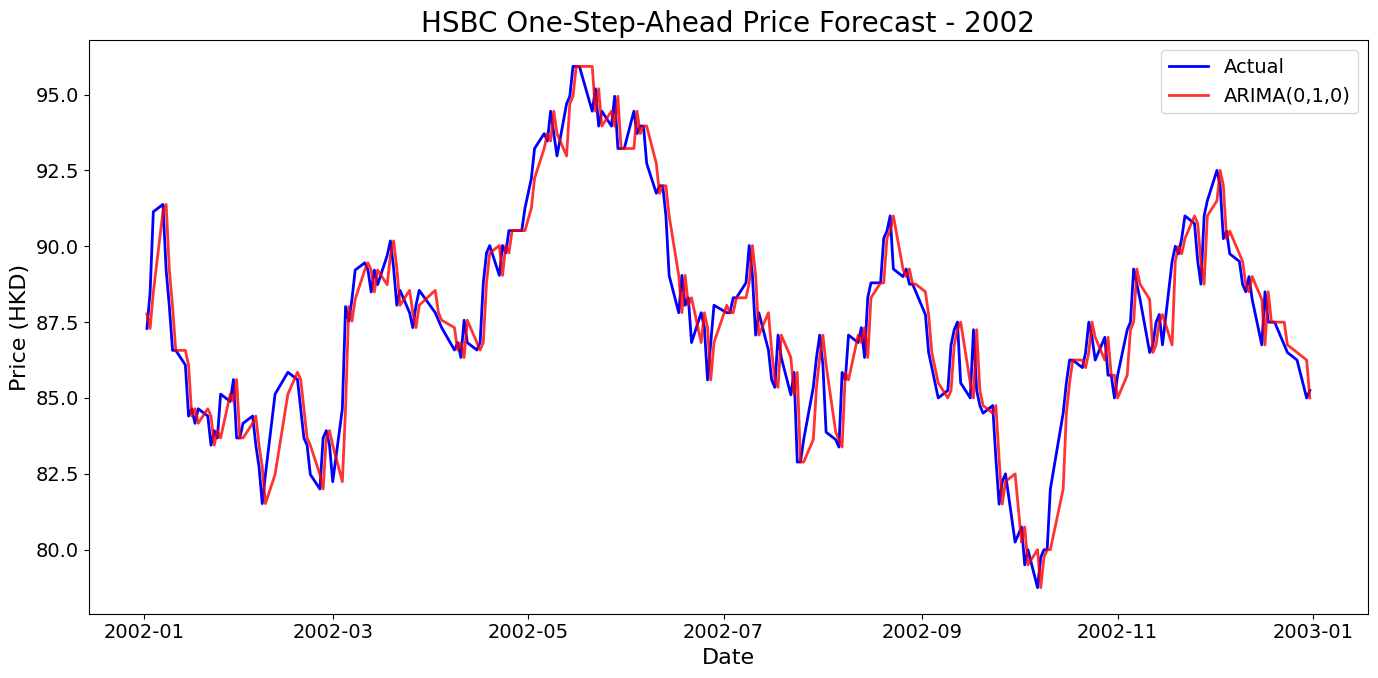

In [10]:
fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(test.index, test.values, "b-", linewidth=2, label="Actual")
ax.plot(test.index, arima_pred, color="red", linewidth=2, alpha=0.8, label=arima_name)
ax.set_title("HSBC One-Step-Ahead Price Forecast - 2002")
ax.set_xlabel("Date")
ax.set_ylabel("Price (HKD)")
ax.legend(fontsize=14)
fig.tight_layout()
fig.savefig("HSBC_forecast.png", dpi=200)
plt.show()

In [11]:
full_price = np.append(train.values[-1], test.values)
rw_mse = np.mean(np.diff(full_price) ** 2)
arima_mse = np.mean((test.values - arima_pred) ** 2)

rw_mae = np.mean(np.abs(np.diff(full_price)))
arima_mae = np.mean(np.abs(test.values - arima_pred))

print(f"{'Metric':<10} {'Random Walk':>14} {arima_name:>14}")
print("-" * 40)
print(f"{'MSE':<10} {rw_mse:>14.4f} {arima_mse:>14.4f}")
print(f"{'MAE':<10} {rw_mae:>14.4f} {arima_mae:>14.4f}")
print(f"\nARIMA MSE vs RW: {(arima_mse/rw_mse - 1)*100:+.2f}%")
print(f"ARIMA MAE vs RW: {(arima_mae/rw_mae - 1)*100:+.2f}%")

Metric        Random Walk   ARIMA(0,1,0)
----------------------------------------
MSE                1.1066         1.1066
MAE                0.8266         0.8266

ARIMA MSE vs RW: +0.00%
ARIMA MAE vs RW: +0.00%

## 11. Forecast Error Analysis

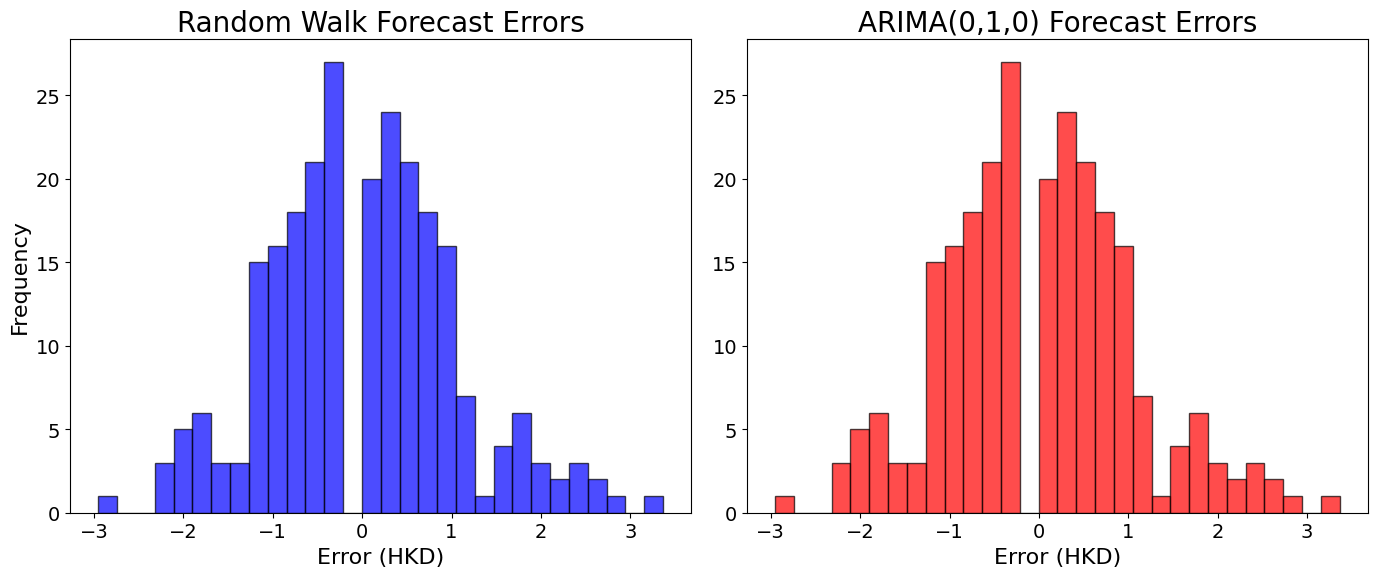

Error Statistics:
                             RW      ARIMA
Mean Error              -0.0102    -0.0102
Std Error                1.0519     1.0519
Median Error             0.0000     0.0000

In [12]:
errors_arima = test.values - arima_pred
errors_rw = np.diff(full_price)

fig, axs = plt.subplots(ncols=2, figsize=(14, 6))

axs[0].hist(errors_rw, bins=30, alpha=0.7, color="blue", edgecolor="black")
axs[0].set_title("Random Walk Forecast Errors")
axs[0].set_xlabel("Error (HKD)")
axs[0].set_ylabel("Frequency")

axs[1].hist(errors_arima, bins=30, alpha=0.7, color="red", edgecolor="black")
axs[1].set_title(f"{arima_name} Forecast Errors")
axs[1].set_xlabel("Error (HKD)")

fig.tight_layout()
fig.savefig("HSBC_error_distributions.png", dpi=200)
plt.show()

print(f"Error Statistics:")
print(f"{'':<20} {'RW':>10} {'ARIMA':>10}")
print(f"{'Mean Error':<20} {np.mean(errors_rw):>10.4f} {np.mean(errors_arima):>10.4f}")
print(f"{'Std Error':<20} {np.std(errors_rw):>10.4f} {np.std(errors_arima):>10.4f}")
print(f"{'Median Error':<20} {np.median(errors_rw):>10.4f} {np.median(errors_arima):>10.4f}")